# 03 · Experiments: DeepLabV3+ variants and backbones

Notebook 02 compared three architectures (baseline CNN, U-Net, DeepLabV3+ with ResNet50). Observations there
led to two questions this notebook answers with a controlled experiment:

1. **Backbone:** does a deeper (ResNet101, ResNet152) or a more efficient (Xception) pretrained encoder help?
2. **Encoder design:** does the **atrous encoder** (AE: full backbone, last stage dilated instead of strided)
   beat the cut-off encoder of the standard variant used here?

| | ResNet101 | ResNet152 | Xception |
|---|---|---|---|
| **DeepLabV3+** (backbone cut after the 1/16 stage) | 36.9 M | 52.6 M | 24.6 M |
| **AE-DeepLabV3+** (full backbone, atrous last stage, output stride 16) | 59.5 M | 75.2 M | 37.7 M |

**Controlled comparison:** all six use the same data, splits, augmentation, loss, optimiser, learning rate
(3e-4), batch size (8, so the largest model fits on the shared GPU), and stopping rules as notebook 02. Only the
model changes. Each experiment is recorded as *hypothesis → result → lesson*.

Runs are resumable: a finished experiment is loaded instead of retrained, so the notebook can be restarted after
an interruption.

In [1]:
import os, shutil, subprocess
if shutil.which("nvidia-smi"):
    free = subprocess.run(["nvidia-smi", "--query-gpu=memory.free", "--format=csv,noheader,nounits"],
                          capture_output=True, text=True).stdout.split()
    os.environ["CUDA_VISIBLE_DEVICES"] = str(max(range(len(free)), key=lambda i: int(free[i])))
    print("Free GPU memory (MB):", free, "-> using GPU", os.environ["CUDA_VISIBLE_DEVICES"])
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
keras.mixed_precision.set_global_policy("mixed_float16")
keras.utils.set_random_seed(42)

from src import config as C, model as M, patching as P, training as T

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

Free GPU memory (MB): ['48539'] -> using GPU 0


/home/jovyan/vault/venv-lulc/lib/python3.11/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.74.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


TensorFlow 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
SMOKE_TEST = False     # True: 64 random patches per split, 2 epochs - only checks that the code runs

BATCH = 8
LR = 3e-4
MAX_EPOCHS = 2 if SMOKE_TEST else 50
PATIENCE = 8

WEIGHTS_DIR = Path(os.environ.get("LULC_WEIGHTS_DIR", ROOT / "weights"))
OUT_DIR = WEIGHTS_DIR / ("experiments_smoke_test" if SMOKE_TEST else "experiments")
OUT_DIR.mkdir(parents=True, exist_ok=True)

stats = M.load_stats()
X_train, y_train, _ = T.load_split("train", smoke=SMOKE_TEST)
X_val, y_val, _ = T.load_split("val", smoke=SMOKE_TEST)
X_test, y_test, meta_test = T.load_split("test", in_memory=False, smoke=SMOKE_TEST)
class_weights = M.median_frequency_weights(P.class_distribution("train").pixels)
data = dict(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, stats=stats, class_weights=class_weights)
print(f"train {len(X_train)} | val {len(X_val)} | test {len(X_test)} patches")

train 14952 | val 1808 | test 4536 patches


## Reference: notebook 02

The three models of notebook 02 (batch 16), for comparison.

In [3]:
reference = {}
results_02 = WEIGHTS_DIR / "results.json"
if results_02.exists():
    r02 = json.loads(results_02.read_text())
    for n, t in r02["training"].items():
        reference[n] = {"params (M)": t["params"] / 1e6, "train mIoU": t["train_mIoU"], "val mIoU": t["val_mIoU"],
                        "gap": t["gap"], "test OA": r02["test"][n]["OA"], "test mIoU": r02["test"][n]["mIoU"],
                        "test mF1": r02["test"][n]["mF1"]}
    display(pd.DataFrame(reference).T.round(4))
else:
    print("Run notebook 02 first to see its results here.")

,params (M),train mIoU,val mIoU,gap,test OA,test mIoU,test mF1
baseline_cnn,0.0756,0.3374,0.3060,0.0313,0.4195,0.2033,0.3031
unet,7.8557,0.5934,0.3813,0.2121,0.4963,0.2746,0.3650
deeplabv3plus,11.8539,0.6189,0.3989,0.2200,0.5104,0.3043,0.4016


In [4]:
runs = {}


def run(name, title):
    model, history, info = T.train_model(name, data, OUT_DIR, lr=LR, batch=BATCH, max_epochs=MAX_EPOCHS,
                                         patience=PATIENCE)
    T.plot_history(history, title)
    test = T.evaluate(model, X_test, y_test, stats)
    runs[name] = dict(title=title, history=history, info=info, test=test)
    del model
    keras.backend.clear_session()
    return pd.Series({**{k: v for k, v in info.items() if k != "verdict"}, "test OA": test["OA"],
                      "test mIoU": test["mIoU"], "test mF1": test["mF1"], "verdict": info["verdict"]})

## E1 · DeepLabV3+ · Xception

Xception replaces ordinary convolutions with depthwise separable ones: far fewer parameters (24.6 M) for a similar receptive field. **Hypothesis:** with only 26 training regions, a leaner encoder overfits less and generalises at least as well as ResNet.

I0000 00:00:1793954949.791941     538 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46732 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:01:00.0, compute capability: 8.6


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
deeplabv3plus_xception: 24,598,768 parameters, batch 8, lr 0.0003
Epoch 1/50


2026-11-06 08:49:14.836932: E tensorflow/core/util/util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


  mIoU train 0.550 | val 0.338   lr 3.0e-04
1869/1869 - 266s - 142ms/step - loss: 1.5682 - val_loss: 2.2730 - val_miou: 0.3377 - val_oa: 0.5894 - train_miou: 0.5499 - train_oa: 0.7602 - learning_rate: 3.0000e-04
Epoch 2/50
  mIoU train 0.520 | val 0.313   lr 3.0e-04
1869/1869 - 203s - 108ms/step - loss: 1.2876 - val_loss: 3.3320 - val_miou: 0.3130 - val_oa: 0.5569 - train_miou: 0.5204 - train_oa: 0.7160 - learning_rate: 3.0000e-04
Epoch 3/50
  mIoU train 0.452 | val 0.300   lr 3.0e-04
1869/1869 - 203s - 109ms/step - loss: 1.1987 - val_loss: 2.4687 - val_miou: 0.3004 - val_oa: 0.5093 - train_miou: 0.4518 - train_oa: 0.6523 - learning_rate: 3.0000e-04
Epoch 4/50
  mIoU train 0.528 | val 0.335   lr 3.0e-04

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
1869/1869 - 203s - 109ms/step - loss: 1.1363 - val_loss: 2.2267 - val_miou: 0.3352 - val_oa: 0.5979 - train_miou: 0.5285 - train_oa: 0.7227 - learning_rate: 3.0000e-04
Epoch 5/50
  mIoU train 0.451 | val 0.326 

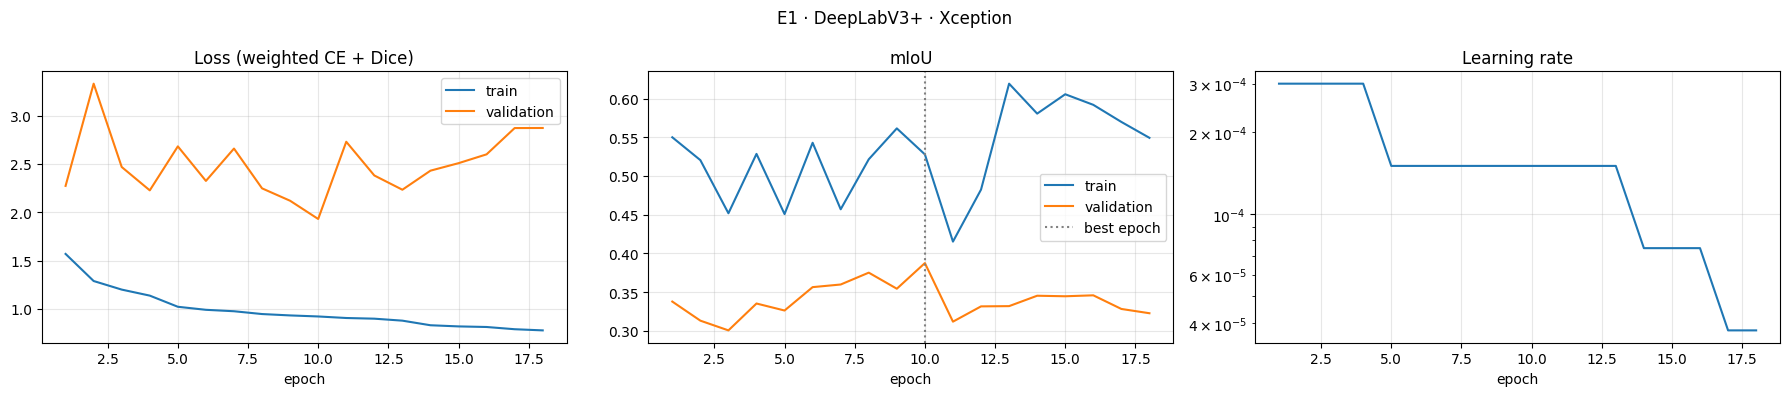

I0000 00:00:1793958687.723876     687 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


params                                                24598768
epochs_run                                                  18
minutes                                                   62.1
batch                                                        8
best_epoch                                                  10
train_mIoU                                              0.5278
val_mIoU                                                0.3874
gap                                                     0.1404
test OA                                               0.430945
test mIoU                                             0.244843
test mF1                                              0.340092
verdict       good fit: training and validation mIoU are close
dtype: object

In [5]:
run("deeplabv3plus_xception", "E1 · DeepLabV3+ · Xception")

## E2 · DeepLabV3+ · ResNet101

Twice as many residual blocks in stage 4 as the ResNet50 model of notebook 02 (36.9 M parameters). **Hypothesis:** deeper features separate classes that need more context (crops vs. rangeland, wetlands).

171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
deeplabv3plus_resnet101: 36,902,472 parameters, batch 8, lr 0.0003
Epoch 1/50


E0000 00:00:1793958792.421824     538 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/deeplabv3plus_resnet101_1/aspp_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  mIoU train 0.303 | val 0.223   lr 3.0e-04
1869/1869 - 322s - 172ms/step - loss: 1.6974 - val_loss: 3.1385 - val_miou: 0.2229 - val_oa: 0.4196 - train_miou: 0.3034 - train_oa: 0.4628 - learning_rate: 3.0000e-04
Epoch 2/50
  mIoU train 0.514 | val 0.314   lr 3.0e-04
1869/1869 - 279s - 149ms/step - loss: 1.4283 - val_loss: 2.4948 - val_miou: 0.3140 - val_oa: 0.5618 - train_miou: 0.5135 - train_oa: 0.7147 - learning_rate: 3.0000e-04
Epoch 3/50
  mIoU train 0.531 | val 0.310   lr 3.0e-04
1869/1869 - 278s - 148ms/step - loss: 1.3001 - val_loss: 2.5215 - val_miou: 0.3104 - val_oa: 0.5211 - train_miou: 0.5310 - train_oa: 0.7156 - learning_rate: 3.0000e-04
Epoch 4/50
  mIoU train 0.287 | val 0.173   lr 3.0e-04
1869/1869 - 277s - 148ms/step - loss: 1.2421 - val_loss: 3.6523 - val_miou: 0.1729 - val_oa: 0.4092 - train_miou: 0.2874 - train_oa: 0.5202 - learning_rate: 3.0000e-04
Epoch 5/50
  mIoU train 0.510 | val 0.288   lr 3.0e-04

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.00015000

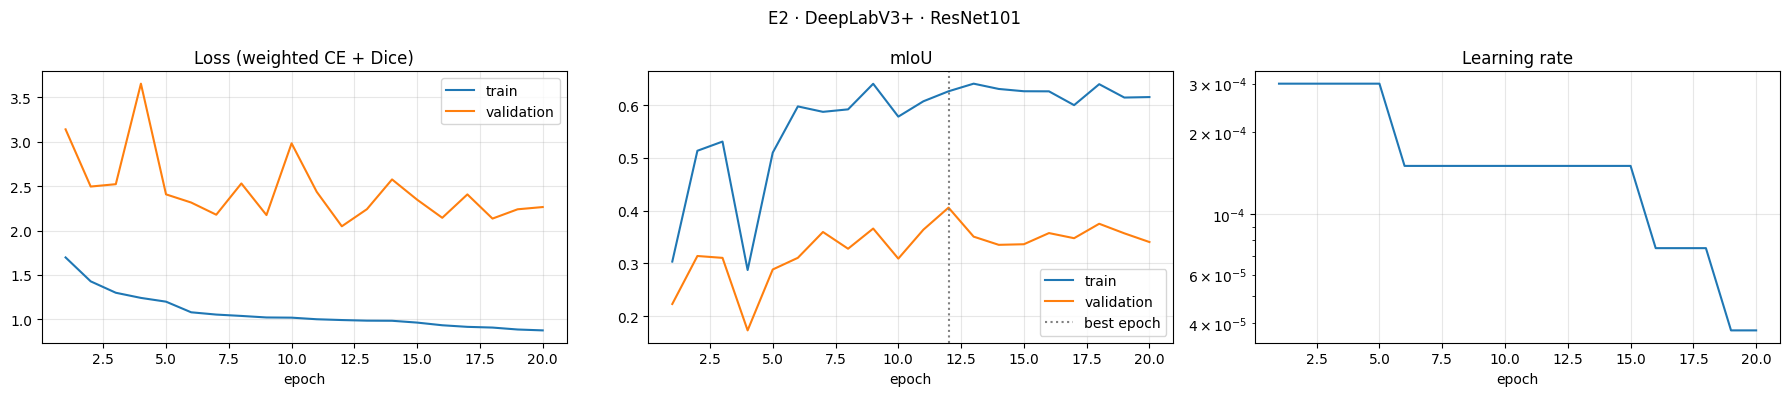

params                                                 36902472
epochs_run                                                   20
minutes                                                    94.4
batch                                                         8
best_epoch                                                   12
train_mIoU                                               0.6264
val_mIoU                                                 0.4057
gap                                                      0.2207
test OA                                                0.496299
test mIoU                                              0.288914
test mF1                                               0.389694
verdict       overfitting: clearly better on training than o...
dtype: object

In [6]:
run("deeplabv3plus_resnet101", "E2 · DeepLabV3+ · ResNet101")

## E3 · DeepLabV3+ · ResNet152

The deepest backbone (52.6 M parameters). **Hypothesis:** returns diminish; more capacity mainly fits the training regions better (larger train–validation gap).

234698864/234698864 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
deeplabv3plus_resnet152: 52,615,240 parameters, batch 8, lr 0.0003
Epoch 1/50


E0000 00:00:1793964538.126611     538 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/deeplabv3plus_resnet152_1/aspp_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  mIoU train 0.274 | val 0.170   lr 3.0e-04
1869/1869 - 451s - 241ms/step - loss: 1.7308 - val_loss: 6.7428 - val_miou: 0.1703 - val_oa: 0.3586 - train_miou: 0.2736 - train_oa: 0.4474 - learning_rate: 3.0000e-04
Epoch 2/50
  mIoU train 0.456 | val 0.299   lr 3.0e-04
1869/1869 - 384s - 205ms/step - loss: 1.4447 - val_loss: 2.4114 - val_miou: 0.2988 - val_oa: 0.5639 - train_miou: 0.4559 - train_oa: 0.6585 - learning_rate: 3.0000e-04
Epoch 3/50
  mIoU train 0.555 | val 0.321   lr 3.0e-04
1869/1869 - 383s - 205ms/step - loss: 1.3917 - val_loss: 2.5169 - val_miou: 0.3205 - val_oa: 0.5778 - train_miou: 0.5550 - train_oa: 0.7662 - learning_rate: 3.0000e-04
Epoch 4/50
  mIoU train 0.542 | val 0.332   lr 3.0e-04
1869/1869 - 384s - 205ms/step - loss: 1.2954 - val_loss: 2.3970 - val_miou: 0.3320 - val_oa: 0.5740 - train_miou: 0.5418 - train_oa: 0.7458 - learning_rate: 3.0000e-04
Epoch 5/50
  mIoU train 0.557 | val 0.368   lr 3.0e-04
1869/1869 - 383s - 205ms/step - loss: 1.2373 - val_loss: 2.1461 

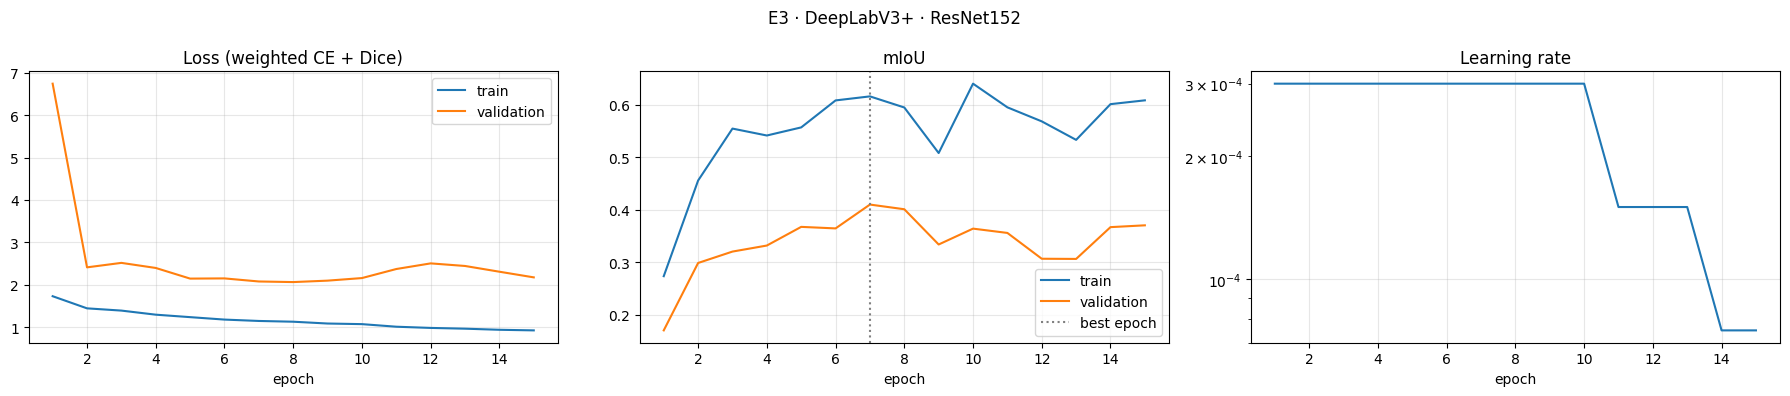

params                                                 52615240
epochs_run                                                   15
minutes                                                    96.7
batch                                                         8
best_epoch                                                    7
train_mIoU                                               0.6164
val_mIoU                                                 0.4102
gap                                                      0.2062
test OA                                                0.468226
test mIoU                                              0.256873
test mF1                                               0.347736
verdict       overfitting: clearly better on training than o...
dtype: object

In [7]:
run("deeplabv3plus_resnet152", "E3 · DeepLabV3+ · ResNet152")

## E4 · AE-DeepLabV3+ · Xception

Atrous encoder: the full Xception including the exit flow, with dilated instead of strided convolutions, so features stay at 1/16 resolution (37.7 M parameters). **Hypothesis:** the larger receptive field helps large homogeneous classes.

ae_deeplabv3plus_xception: 37,706,480 parameters, batch 8, lr 0.0003
Epoch 1/50


E0000 00:00:1793970346.699799     538 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/ae_deeplabv3plus_xception_1/aspp_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  mIoU train 0.516 | val 0.347   lr 3.0e-04
1869/1869 - 248s - 133ms/step - loss: 1.6655 - val_loss: 2.1571 - val_miou: 0.3471 - val_oa: 0.5964 - train_miou: 0.5157 - train_oa: 0.7195 - learning_rate: 3.0000e-04
Epoch 2/50
  mIoU train 0.459 | val 0.276   lr 3.0e-04
1869/1869 - 227s - 122ms/step - loss: 1.3981 - val_loss: 2.7296 - val_miou: 0.2758 - val_oa: 0.4997 - train_miou: 0.4589 - train_oa: 0.6614 - learning_rate: 3.0000e-04
Epoch 3/50
  mIoU train 0.457 | val 0.292   lr 3.0e-04
1869/1869 - 228s - 122ms/step - loss: 1.2814 - val_loss: 2.6108 - val_miou: 0.2925 - val_oa: 0.5241 - train_miou: 0.4567 - train_oa: 0.6662 - learning_rate: 3.0000e-04
Epoch 4/50
  mIoU train 0.461 | val 0.282   lr 3.0e-04

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
1869/1869 - 227s - 121ms/step - loss: 1.2303 - val_loss: 2.7334 - val_miou: 0.2823 - val_oa: 0.5062 - train_miou: 0.4609 - train_oa: 0.6376 - learning_rate: 3.0000e-04
Epoch 5/50
  mIoU train 0.469 | val 0.296 

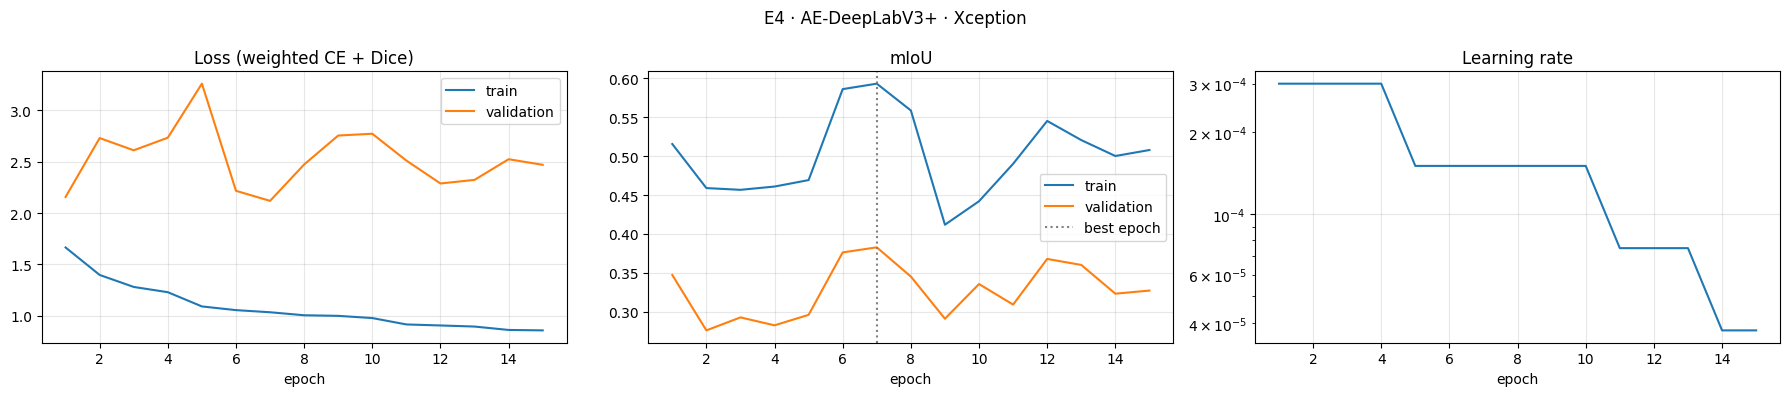

2026-11-06 14:02:49.191523: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-06 14:02:49.319468: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-06 14:02:50.433464: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-06 14:02:50.558636: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-06 14:02:51.190599: E external/local_xla/xla/stream_

params                                                 37706480
epochs_run                                                   15
minutes                                                    57.2
batch                                                         8
best_epoch                                                    7
train_mIoU                                               0.5933
val_mIoU                                                 0.3827
gap                                                      0.2107
test OA                                                0.486813
test mIoU                                              0.270039
test mF1                                               0.368963
verdict       overfitting: clearly better on training than o...
dtype: object

In [8]:
run("ae_deeplabv3plus_xception", "E4 · AE-DeepLabV3+ · Xception")

## E5 · AE-DeepLabV3+ · ResNet101

Full ResNet101 with a dilated stage 5 (59.5 M parameters). Compared with the cut-off DeepLabV3+ · ResNet101, this isolates the effect of the atrous encoder.

ae_deeplabv3plus_resnet101: 59,503,176 parameters, batch 8, lr 0.0003
Epoch 1/50


E0000 00:00:1793973865.247912     538 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/ae_deeplabv3plus_resnet101_1/aspp_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  mIoU train 0.484 | val 0.342   lr 3.0e-04
1869/1869 - 378s - 202ms/step - loss: 1.7320 - val_loss: 2.5453 - val_miou: 0.3416 - val_oa: 0.5730 - train_miou: 0.4838 - train_oa: 0.6945 - learning_rate: 3.0000e-04
Epoch 2/50
  mIoU train 0.356 | val 0.222   lr 3.0e-04
1869/1869 - 329s - 176ms/step - loss: 1.4191 - val_loss: 3.0127 - val_miou: 0.2216 - val_oa: 0.4124 - train_miou: 0.3562 - train_oa: 0.5421 - learning_rate: 3.0000e-04
Epoch 3/50
  mIoU train 0.523 | val 0.327   lr 3.0e-04
1869/1869 - 329s - 176ms/step - loss: 1.3084 - val_loss: 2.5342 - val_miou: 0.3267 - val_oa: 0.5631 - train_miou: 0.5228 - train_oa: 0.7129 - learning_rate: 3.0000e-04
Epoch 4/50
  mIoU train 0.548 | val 0.336   lr 3.0e-04

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
1869/1869 - 329s - 176ms/step - loss: 1.2594 - val_loss: 2.3544 - val_miou: 0.3362 - val_oa: 0.5762 - train_miou: 0.5480 - train_oa: 0.7435 - learning_rate: 3.0000e-04
Epoch 5/50
  mIoU train 0.579 | val 0.356 

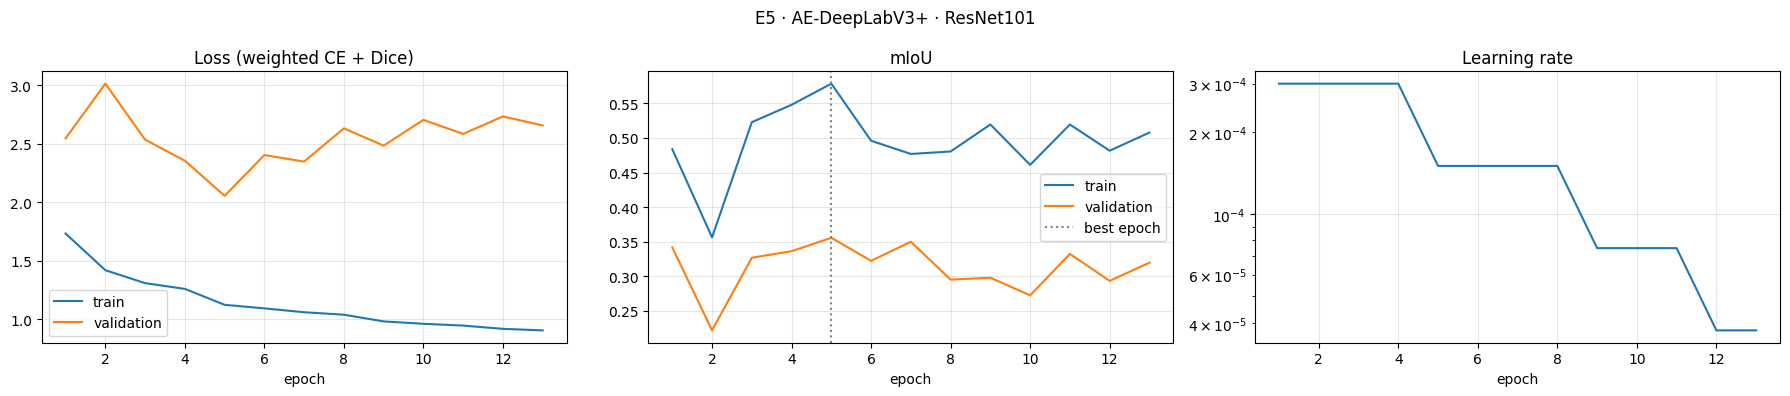

params                                                 59503176
epochs_run                                                   13
minutes                                                    72.1
batch                                                         8
best_epoch                                                    5
train_mIoU                                               0.5786
val_mIoU                                                 0.3555
gap                                                      0.2231
test OA                                                0.510509
test mIoU                                              0.297036
test mF1                                               0.397071
verdict       overfitting: clearly better on training than o...
dtype: object

In [9]:
run("ae_deeplabv3plus_resnet101", "E5 · AE-DeepLabV3+ · ResNet101")

## E6 · AE-DeepLabV3+ · ResNet152

The largest model (75.2 M parameters). **Hypothesis:** the most prone to overfitting; only worth it if the validation mIoU clearly improves.

ae_deeplabv3plus_resnet152: 75,215,944 parameters, batch 8, lr 0.0003
Epoch 1/50


E0000 00:00:1793978264.593885     538 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/ae_deeplabv3plus_resnet152_1/aspp_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  mIoU train 0.371 | val 0.236   lr 3.0e-04
1869/1869 - 507s - 271ms/step - loss: 1.8509 - val_loss: 4.5479 - val_miou: 0.2359 - val_oa: 0.4218 - train_miou: 0.3712 - train_oa: 0.5500 - learning_rate: 3.0000e-04
Epoch 2/50
  mIoU train 0.507 | val 0.323   lr 3.0e-04
1869/1869 - 436s - 233ms/step - loss: 1.5195 - val_loss: 2.5871 - val_miou: 0.3229 - val_oa: 0.5628 - train_miou: 0.5068 - train_oa: 0.7137 - learning_rate: 3.0000e-04
Epoch 3/50
  mIoU train 0.361 | val 0.263   lr 3.0e-04
1869/1869 - 433s - 232ms/step - loss: 1.3828 - val_loss: 2.5673 - val_miou: 0.2630 - val_oa: 0.4677 - train_miou: 0.3613 - train_oa: 0.5280 - learning_rate: 3.0000e-04
Epoch 4/50
  mIoU train 0.478 | val 0.309   lr 3.0e-04
1869/1869 - 433s - 232ms/step - loss: 1.3033 - val_loss: 2.5508 - val_miou: 0.3087 - val_oa: 0.5405 - train_miou: 0.4781 - train_oa: 0.6764 - learning_rate: 3.0000e-04
Epoch 5/50
  mIoU train 0.436 | val 0.271   lr 3.0e-04

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.00015000

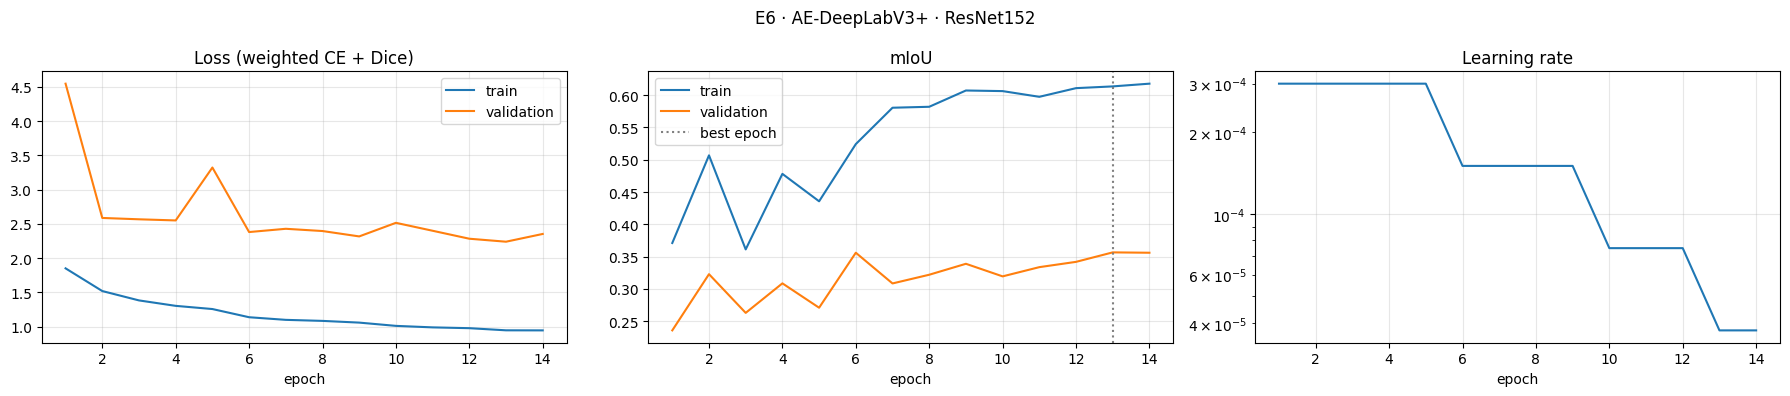

params                                                 75215944
epochs_run                                                   14
minutes                                                   102.3
batch                                                         8
best_epoch                                                   13
train_mIoU                                               0.6135
val_mIoU                                                 0.3566
gap                                                      0.2568
test OA                                                0.517917
test mIoU                                              0.298725
test mF1                                               0.404552
verdict       overfitting: clearly better on training than o...
dtype: object

In [10]:
run("ae_deeplabv3plus_resnet152", "E6 · AE-DeepLabV3+ · ResNet152")

## Comparison

In [11]:
rows = {}
for n, r in runs.items():
    i, t = r["info"], r["test"]
    rows[r["title"]] = {"params (M)": i["params"] / 1e6, "epochs": i["epochs_run"], "best epoch": i["best_epoch"],
                        "minutes": i["minutes"], "train mIoU": i["train_mIoU"], "val mIoU": i["val_mIoU"],
                        "gap": i["gap"], "test OA": t["OA"], "test mIoU": t["mIoU"], "test mF1": t["mF1"],
                        "verdict": i["verdict"]}
comparison = pd.DataFrame(rows).T
comparison

,params (M),epochs,best epoch,minutes,train mIoU,val mIoU,gap,test OA,test mIoU,test mF1,verdict
E1 · DeepLabV3+ · Xception,24.598768,18,10,62.1,0.5278,0.3874,0.1404,0.430945,0.244843,0.340092,good fit: training and validation mIoU are close
E2 · DeepLabV3+ · ResNet101,36.902472,20,12,94.4,0.6264,0.4057,0.2207,0.496299,0.288914,0.389694,overfitting: clearly better on training than o...
E3 · DeepLabV3+ · ResNet152,52.61524,15,7,96.7,0.6164,0.4102,0.2062,0.468226,0.256873,0.347736,overfitting: clearly better on training than o...
E4 · AE-DeepLabV3+ · Xception,37.70648,15,7,57.2,0.5933,0.3827,0.2107,0.486813,0.270039,0.368963,overfitting: clearly better on training than o...
E5 · AE-DeepLabV3+ · ResNet101,59.503176,13,5,72.1,0.5786,0.3555,0.2231,0.510509,0.297036,0.397071,overfitting: clearly better on training than o...
E6 · AE-DeepLabV3+ · ResNet152,75.215944,14,13,102.3,0.6135,0.3566,0.2568,0.517917,0.298725,0.404552,overfitting: clearly better on training than o...


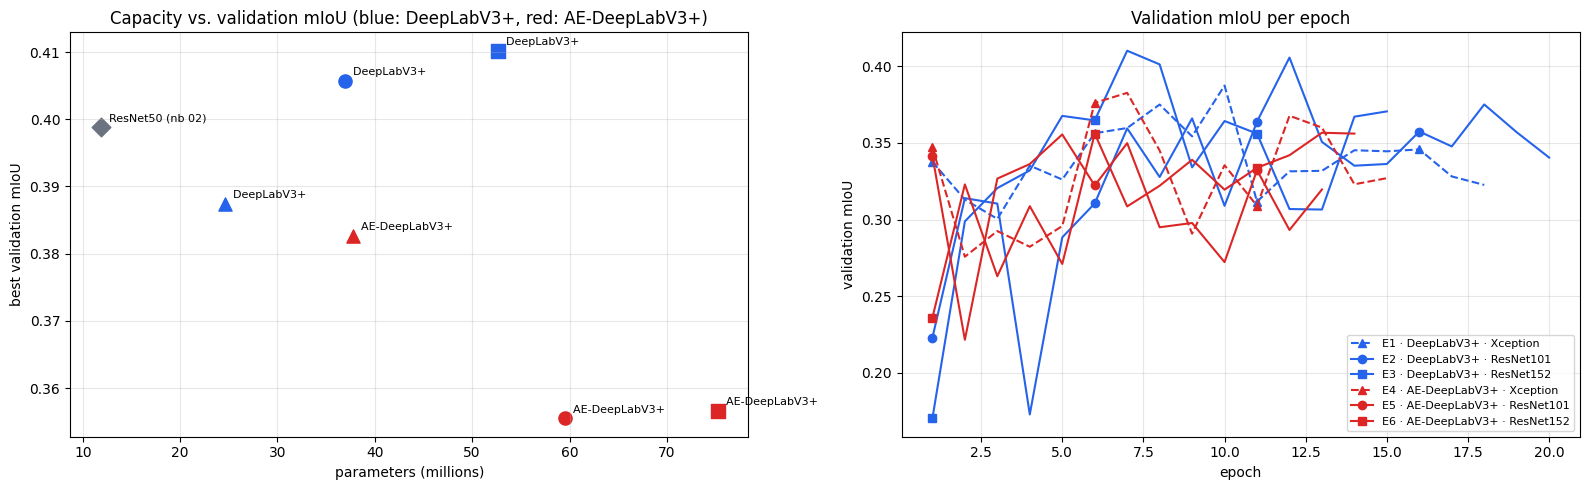

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
markers = {"resnet101": "o", "resnet152": "s", "xception": "^"}
for n, r in runs.items():
    backbone = n.split("_")[-1]
    color = "#dc2626" if n.startswith("ae_") else "#2563eb"
    ax[0].scatter(r["info"]["params"] / 1e6, r["info"]["val_mIoU"], marker=markers[backbone], color=color, s=90)
    ax[0].annotate(r["title"].split("· ")[1], (r["info"]["params"] / 1e6, r["info"]["val_mIoU"]),
                   textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax[1].plot(r["history"].val_miou, color=color, ls="-" if backbone != "xception" else "--",
               marker=markers[backbone], markevery=5, label=r["title"])
for n, ref in reference.items():
    if n == "deeplabv3plus":
        ax[0].scatter(ref["params (M)"], ref["val mIoU"], marker="D", color="#6b7280", s=90)
        ax[0].annotate("ResNet50 (nb 02)", (ref["params (M)"], ref["val mIoU"]), textcoords="offset points",
                       xytext=(6, 4), fontsize=8)
ax[0].set_xlabel("parameters (millions)"); ax[0].set_ylabel("best validation mIoU")
ax[0].set_title("Capacity vs. validation mIoU (blue: DeepLabV3+, red: AE-DeepLabV3+)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation mIoU"); ax[1].set_title("Validation mIoU per epoch")
ax[1].legend(fontsize=8)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "experiments_comparison.png", dpi=150)
plt.show()

### Effect of the atrous encoder (AE minus standard, same backbone)

In [13]:
effect = {}
for b in M.BACKBONES:
    std, ae = runs.get(f"deeplabv3plus_{b}"), runs.get(f"ae_deeplabv3plus_{b}")
    if std and ae:
        effect[b] = {"Δ val mIoU": ae["info"]["val_mIoU"] - std["info"]["val_mIoU"],
                     "Δ test mIoU": ae["test"]["mIoU"] - std["test"]["mIoU"],
                     "Δ gap": ae["info"]["gap"] - std["info"]["gap"],
                     "Δ params (M)": (ae["info"]["params"] - std["info"]["params"]) / 1e6}
pd.DataFrame(effect).T.round(4)

,Δ val mIoU,Δ test mIoU,Δ gap,Δ params (M)
resnet101,-0.0502,0.0081,0.0024,22.6007
resnet152,-0.0536,0.0419,0.0506,22.6007
xception,-0.0047,0.0252,0.0703,13.1077


### Per-class test IoU

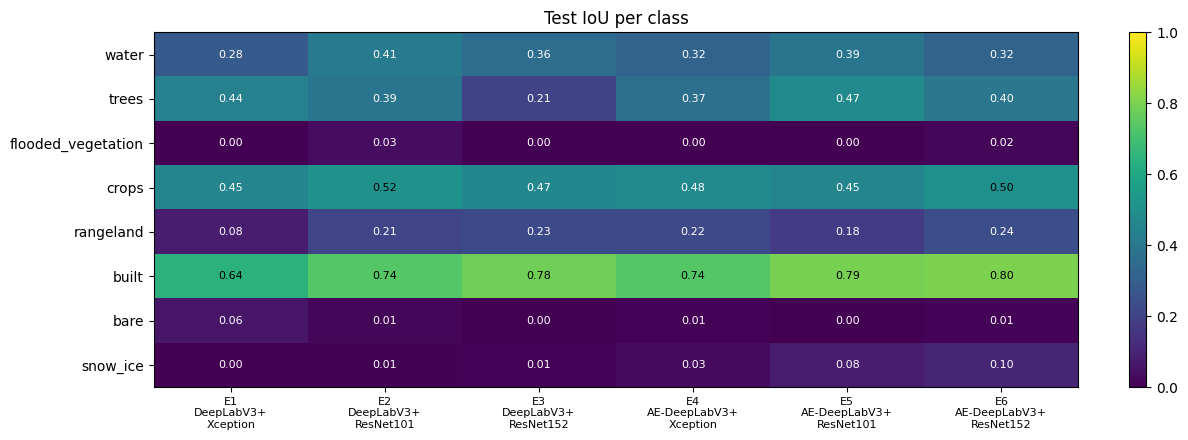

In [14]:
per_class = pd.DataFrame({r["title"]: r["test"]["per_class"]["IoU"] for r in runs.values()})
fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(per_class.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(per_class)), per_class.index)
ax.set_xticks(range(per_class.shape[1]), [c.replace(" · ", "\n") for c in per_class.columns], fontsize=8)
for i in range(per_class.shape[0]):
    for j in range(per_class.shape[1]):
        v = per_class.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v < 0.5 else "black")
plt.colorbar(im, fraction=0.03)
ax.set_title("Test IoU per class")
plt.tight_layout()
plt.savefig(OUT_DIR / "experiments_per_class_iou.png", dpi=150)
plt.show()

## Findings

*(Written after the run, one line per experiment: was the hypothesis confirmed, and what does it teach?)*

| Experiment | Hypothesis confirmed? | Lesson |
|---|---|---|
| E1 · Xception | | |
| E2 · ResNet101 | | |
| E3 · ResNet152 | | |
| E4 · AE Xception | | |
| E5 · AE ResNet101 | | |
| E6 · AE ResNet152 | | |

**Selection:** the experiment with the highest *validation* mIoU is saved as
`weights/experiments/best_experiment.keras`. It replaces the notebook-02 model in the prototype only if its
validation mIoU is higher.

In [15]:
summary = {n: {"title": r["title"], **{k: v for k, v in r["info"].items()},
                "test": {"OA": float(r["test"]["OA"]), "mIoU": float(r["test"]["mIoU"]), "mF1": float(r["test"]["mF1"]),
                         "per_class_IoU": r["test"]["per_class"]["IoU"].round(4).to_dict(),
                         "per_class_F1": r["test"]["per_class"]["F1"].round(4).to_dict()}}
           for n, r in runs.items()}
(OUT_DIR / "experiments_results.json").write_text(json.dumps(summary, indent=2, default=float))

best = max(runs, key=lambda n: runs[n]["info"]["val_mIoU"])
shutil.copy(OUT_DIR / f"{best}.keras", OUT_DIR / "best_experiment.keras")
ref_val = reference.get(json.loads(results_02.read_text())["selected_model"], {}).get("val mIoU") if results_02.exists() else None
print(f"Best experiment on validation mIoU: {runs[best]['title']} ({runs[best]['info']['val_mIoU']:.4f})")
print(f"Notebook-02 selected model: {ref_val}")
if ref_val is not None and runs[best]["info"]["val_mIoU"] > ref_val:
    print("-> better than notebook 02: use weights/experiments/best_experiment.keras in the prototype")
else:
    print("-> not better than notebook 02: the prototype keeps weights/best_model.keras")

Best experiment on validation mIoU: E3 · DeepLabV3+ · ResNet152 (0.4102)
Notebook-02 selected model: 0.3989
-> better than notebook 02: use weights/experiments/best_experiment.keras in the prototype
